In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/mobile_addiction_data.csv')

In [3]:
df.head()

,User_ID,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,...,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Self_Reported_Addiction_Level,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score
0,1,India,32,Male,Salesperson,High School,43865.49,5.81,75,0.84,...,1.85,5G,Other,No,Low,16.43,Yes,16,106,39.36
1,2,UK,26,Male,Artist,Master's,41868.19,9.05,61,3.13,...,0.66,4G,Samsung,Yes,Severe,32.87,No,12,111,9.45
2,3,Germany,70,Other,Doctor,High School,59636.51,5.76,58,2.12,...,-0.14,WiFi,Samsung,Yes,Severe,27.45,No,18,90,50.27
3,4,UK,44,Female,Engineer,NaN,39022.07,6.71,80,1.60,...,0.17,3G,Apple,Yes,Moderate,30.85,No,17,60,30.82
4,5,Brazil,46,Other,Student,NaN,-783.98,6.31,136,1.51,...,0.58,3G,Xiaomi,No,High,10.38,Yes,18,127,21.70


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   User_ID                         3000 non-null   int64  
 1   Country                         3000 non-null   object 
 2   Age                             3000 non-null   int64  
 3   Gender                          3000 non-null   object 
 4   Occupation                      3000 non-null   object 
 5   Education_Level                 2388 non-null   object 
 6   Income_USD                      3000 non-null   float64
 7   Daily_Screen_Time_Hours         3000 non-null   float64
 8   Phone_Unlocks_Per_Day           3000 non-null   int64  
 9   Social_Media_Usage_Hours        3000 non-null   float64
 10  Gaming_Usage_Hours              3000 non-null   float64
 11  Streaming_Usage_Hours           3000 non-null   float64
 12  Messaging_Usage_Hours           30

In [5]:
df = df.drop('User_ID', axis=1)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Country                         3000 non-null   object 
 1   Age                             3000 non-null   int64  
 2   Gender                          3000 non-null   object 
 3   Occupation                      3000 non-null   object 
 4   Education_Level                 2388 non-null   object 
 5   Income_USD                      3000 non-null   float64
 6   Daily_Screen_Time_Hours         3000 non-null   float64
 7   Phone_Unlocks_Per_Day           3000 non-null   int64  
 8   Social_Media_Usage_Hours        3000 non-null   float64
 9   Gaming_Usage_Hours              3000 non-null   float64
 10  Streaming_Usage_Hours           3000 non-null   float64
 11  Messaging_Usage_Hours           3000 non-null   float64
 12  Work_Related_Usage_Hours        30

In [7]:
df['Education_Level'].unique()

array(['High School', "Master's", nan, 'PhD', "Bachelor's"], dtype=object)

In [8]:
df['Education_Level'].value_counts()

Education_Level
High School    621
Master's       616
PhD            578
Bachelor's     573
Name: count, dtype: int64

In [9]:
df['Self_Reported_Addiction_Level'].value_counts()

Self_Reported_Addiction_Level
High        764
Low         756
Severe      750
Moderate    730
Name: count, dtype: int64

<Axes: xlabel='Self_Reported_Addiction_Level', ylabel='count'>

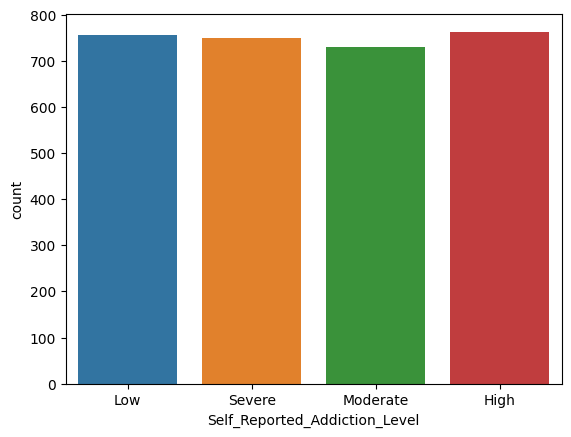

In [10]:
sns.countplot(x='Self_Reported_Addiction_Level', data=df, hue='Self_Reported_Addiction_Level')

In [11]:
df['Self_Reported_Addiction_Level'] = df['Self_Reported_Addiction_Level'].map({'Low': 0, 'Moderate': 0, 'High': 1, 'Severe': 1})

<Axes: xlabel='Self_Reported_Addiction_Level', ylabel='count'>

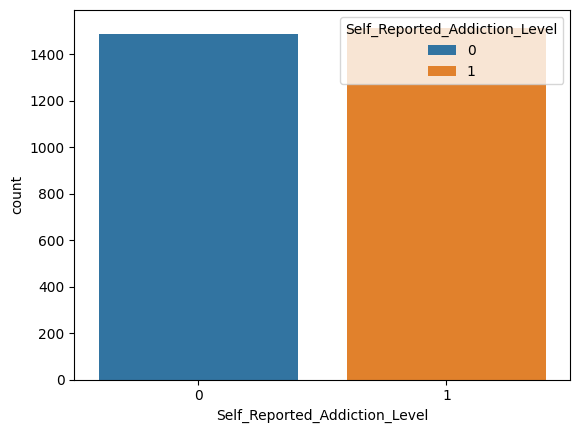

In [12]:
sns.countplot(x='Self_Reported_Addiction_Level', data=df, hue='Self_Reported_Addiction_Level')

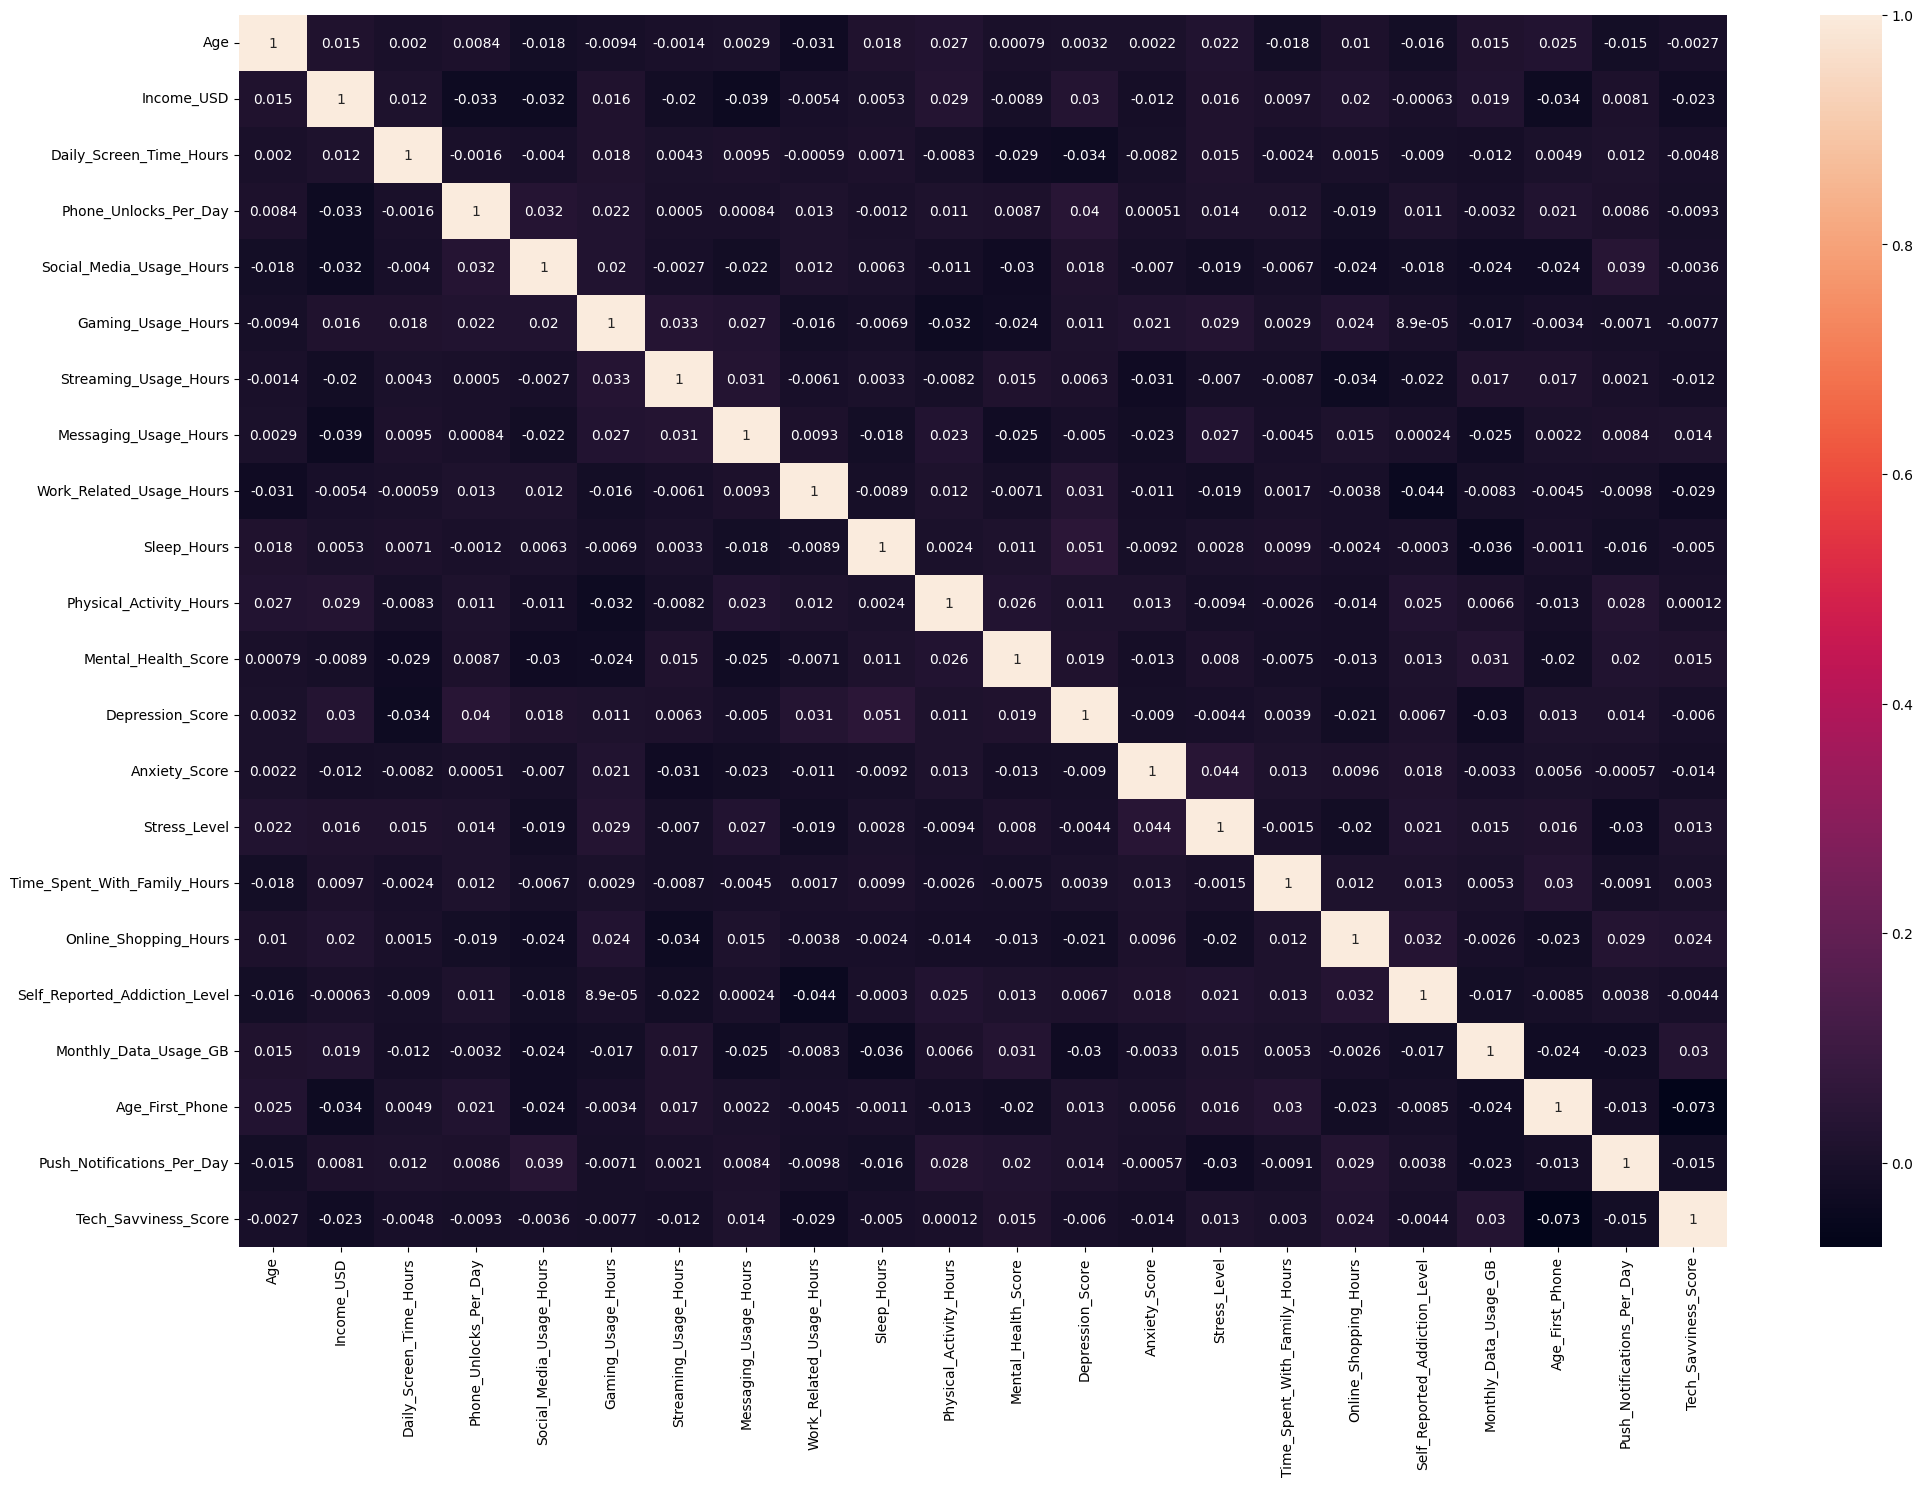

In [125]:
plt.figure(figsize=(24, 16))
sns.heatmap(df.corr(numeric_only=True), annot=True);

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import SimpleImputer, KNNImputer

In [14]:
X = df.drop('Self_Reported_Addiction_Level', axis=1)

In [15]:
y = df['Self_Reported_Addiction_Level']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=104, stratify=y)

In [17]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

In [18]:
num_features

['Age',
 'Income_USD',
 'Daily_Screen_Time_Hours',
 'Phone_Unlocks_Per_Day',
 'Social_Media_Usage_Hours',
 'Gaming_Usage_Hours',
 'Streaming_Usage_Hours',
 'Messaging_Usage_Hours',
 'Work_Related_Usage_Hours',
 'Sleep_Hours',
 'Physical_Activity_Hours',
 'Mental_Health_Score',
 'Depression_Score',
 'Anxiety_Score',
 'Stress_Level',
 'Time_Spent_With_Family_Hours',
 'Online_Shopping_Hours',
 'Monthly_Data_Usage_GB',
 'Age_First_Phone',
 'Push_Notifications_Per_Day',
 'Tech_Savviness_Score']

In [19]:
cat_features

['Country',
 'Gender',
 'Occupation',
 'Education_Level',
 'Relationship_Status',
 'Has_Children',
 'Urban_or_Rural',
 'Internet_Connection_Type',
 'Primary_Device_Brand',
 'Has_Screen_Time_Management_App',
 'Has_Night_Mode_On']

In [20]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [21]:
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_transformer, cat_features),
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [158]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10, 100, 1000],
                                   cv=10,
                                  penalty='l2',
                                  solver='lbfgs',
                                  max_iter=100_000,
                                  n_jobs=-1,
                                  random_state=104))
])

In [159]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [160]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [161]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [162]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
roc_auc_train = roc_auc_score(y_train, y_train_proba)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)

In [191]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [10.]


In [164]:
accuracy

0.5533333333333333

In [165]:
precision

0.5620437956204379

In [166]:
recall

0.5099337748344371

In [167]:
roc_auc_train

0.5748675734539992

In [168]:
roc_auc_test

0.5602915685141562

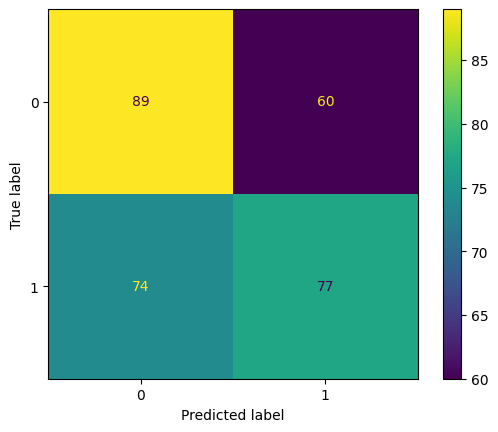

In [169]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test);

In [170]:
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [171]:
y_full_proba = pipe.predict_proba(X)[:, 1]

In [190]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")
print(f"Лучшее значение l1_ratio: {best_final_model.l1_ratio_}")

Лучшее значение C: [10.]
Лучшее значение l1_ratio: [None]


In [173]:
roc_auc_full = roc_auc_score(y, y_full_proba)

In [174]:
roc_auc_full

0.5771151620318926

In [175]:
df[df['Self_Reported_Addiction_Level'] == 'Low'].head(2)

,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,Gaming_Usage_Hours,...,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Self_Reported_Addiction_Level,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score


In [176]:
df[df['Self_Reported_Addiction_Level'] == 'Moderate'].head(2)

,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,Gaming_Usage_Hours,...,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Self_Reported_Addiction_Level,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score


In [177]:
df[df['Self_Reported_Addiction_Level'] == 'High'].head(2)

,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,Gaming_Usage_Hours,...,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Self_Reported_Addiction_Level,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score


In [178]:
df[df['Self_Reported_Addiction_Level'] == 'Severe'].head(2)

,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,Gaming_Usage_Hours,...,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Self_Reported_Addiction_Level,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score


In [179]:
import pandas as pd
import numpy as np

real_multiclass_data = {
    'Country': ['United States', 'India', 'United Kingdom', 'China'],
    'Age': [25, 25, 25, 25],
    'Gender': ['Male', 'Female', 'Male', 'Female'],
    'Occupation': ['Professional', 'Student', 'Manager', 'Student'],
    'Education_Level': ['Bachelors', 'High School', 'Masters', 'Bachelors'],
    'Income_USD': [20_000.0, 20_000.0, 20_000.0, 20_000.0],
    'Daily_Screen_Time_Hours': [1.5, 4.5, 7.5, 12.0],
    'Phone_Unlocks_Per_Day': [15, 45, 90, 180],
    'Social_Media_Usage_Hours': [0.5, 2.5, 4.0, 7.0],
    'Gaming_Usage_Hours': [0.0, 1.0, 2.0, 4.0],
    'Streaming_Usage_Hours': [0.5, 1.5, 2.5, 5.0],
    'Messaging_Usage_Hours': [0.5, 1.5, 3.0, 6.0],
    'Work_Related_Usage_Hours': [2.0, 0.0, 4.0, 0.0],
    'Sleep_Hours': [8.0, 7.0, 5.5, 4.0],
    'Physical_Activity_Hours': [2.0, 1.0, 0.5, 0.0],
    'Mental_Health_Score': [99.0, 70.0, 40.0, 5.0],
    'Depression_Score': [5.0, 25.0, 65.0, 99.0],
    'Anxiety_Score': [5.0, 30.0, 70.0, 99.0],
    'Stress_Level': [20.0, 45.0, 75.0, 98.0],
    'Relationship_Status': ['Married', 'Single', 'Divorced', 'Single'],
    'Has_Children': ['Yes', 'No', 'Yes', 'No'],
    'Urban_or_Rural': ['Urban', 'Urban', 'Rural', 'Urban'],
    'Time_Spent_With_Family_Hours': [3.0, 2.0, 1.0, 0.0],
    'Online_Shopping_Hours': [0.5, 1.0, 2.5, 4.5],
    'Internet_Connection_Type': ['Wi-Fi', 'Mobile Data', 'Wi-Fi', 'Mobile Data'],
    'Primary_Device_Brand': ['Apple', 'Samsung', 'Google', 'Xiaomi'],
    'Has_Screen_Time_Management_App': ['Yes', 'No', 'No', 'No'],
    'Monthly_Data_Usage_GB': [15.0, 45.0, 80.0, 250.0],
    'Has_Night_Mode_On': ['Yes', 'Yes', 'No', 'No'],
    'Age_First_Phone': [18, 14, 11, 8],
    'Push_Notifications_Per_Day': [10, 40, 120, 350],
    'Tech_Savviness_Score': [50.0, 50.0, 50.0, 50.0],
}
test_df_real = pd.DataFrame(real_multiclass_data)

In [180]:
test_df_real

,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,Gaming_Usage_Hours,...,Time_Spent_With_Family_Hours,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score
0,United States,25,Male,Professional,Bachelors,20000.0,1.5,15,0.5,0.0,...,3.0,0.5,Wi-Fi,Apple,Yes,15.0,Yes,18,10,50.0
1,India,25,Female,Student,High School,20000.0,4.5,45,2.5,1.0,...,2.0,1.0,Mobile Data,Samsung,No,45.0,Yes,14,40,50.0
2,United Kingdom,25,Male,Manager,Masters,20000.0,7.5,90,4.0,2.0,...,1.0,2.5,Wi-Fi,Google,No,80.0,No,11,120,50.0
3,China,25,Female,Student,Bachelors,20000.0,12.0,180,7.0,4.0,...,0.0,4.5,Mobile Data,Xiaomi,No,250.0,No,8,350,50.0


In [181]:
predictions = pipe.predict(test_df_real)
probabilities = pipe.predict_proba(test_df_real)

In [182]:
class_labels = {0: 'Low', 1: 'Low', 2: 'High', 3:'High'}
pred = {0: 'Low', 1: 'High'}

print("="*65)
print("🦾 ВЕРДИКТ ТВОЕГО РЕАЛЬНОГО МНОГОКЛАССОВОГО ИИ:")
print("="*65)

for i in range(4):
    pred_class = predictions[i]
    print(f"Пользователь №{i+1}:")
    print(f"  -> Ожидаемый профиль:     {class_labels[i]}")
    print(f"  -> Предсказание модели:    Класс {pred_class} ({pred[pred_class]})")
    print(f"  -> Вероятности [Low, Moderate, High, Severe]:")
    print(f"      {np.round(probabilities[i], 4)}")
    print("-"*65)

🦾 ВЕРДИКТ ТВОЕГО РЕАЛЬНОГО МНОГОКЛАССОВОГО ИИ:
Пользователь №1:
  -> Ожидаемый профиль:     Low
  -> Предсказание модели:    Класс 1 (High)
  -> Вероятности [Low, Moderate, High, Severe]:
      [0.4664 0.5336]
-----------------------------------------------------------------
Пользователь №2:
  -> Ожидаемый профиль:     Low
  -> Предсказание модели:    Класс 0 (Low)
  -> Вероятности [Low, Moderate, High, Severe]:
      [0.568 0.432]
-----------------------------------------------------------------
Пользователь №3:
  -> Ожидаемый профиль:     High
  -> Предсказание модели:    Класс 0 (Low)
  -> Вероятности [Low, Moderate, High, Severe]:
      [0.5102 0.4898]
-----------------------------------------------------------------
Пользователь №4:
  -> Ожидаемый профиль:     High
  -> Предсказание модели:    Класс 0 (Low)
  -> Вероятности [Low, Moderate, High, Severe]:
      [0.5791 0.4209]
-----------------------------------------------------------------


In [183]:
class_percents = df['Self_Reported_Addiction_Level'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 49.5%, 1: 50.5%


In [184]:
import json
import os

advanced_report = {
    "project": "Mobile Phone Addiction Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [185]:
from joblib import dump, load

In [186]:
dump(pipe, "model/mobile_phone_addiction_logistic_regression_cv_2026_v1.pkl")

['model/mobile_phone_addiction_logistic_regression_cv_2026_v1.pkl']

In [187]:
loaded_pipe = load("model/mobile_phone_addiction_logistic_regression_cv_2026_v1.pkl")

In [188]:
loaded_pipe.predict(test_df_real)

array([1, 0, 0, 0])

In [189]:
loaded_pipe.predict_proba(test_df_real)

array([[0.46640382, 0.53359618],
       [0.56803202, 0.43196798],
       [0.5102415 , 0.4897585 ],
       [0.57913741, 0.42086259]])